<a href="https://colab.research.google.com/github/PabloVidal000/Telecom-analysis-/blob/main/S8_Student_Version_Project_NovaRetail_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto 7 - Explorando factores de comportamiento en NovaRetail+


NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ causalidad.**

## Sección 1 - Cargar y explorar el dataset

En esta sección validamos:
- que el dataset cargue correctamente
- tipos de datos
- valores faltantes / rangos generales

Antes de correlacionar, primero entendemos el “terreno”.

In [ ]:
# Importar librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sn
from scipy.stats import pearsonr, spearmanr, pointbiserialr as pb, chi2_contingency as chi2



### Cargar Dataset

In [ ]:
# Cargar el dataset y explorar datos
df = pd.read_csv('/datasets/novaretail_comportamiento_clientes_2024.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


#### Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.


In [ ]:
# mostrar las primeras 5 filas
df.head()

,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


## Sección 2 - Preparar datos y documentar supuestos

### Exploración y Limpieza

#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:
- `edad` (`int64`)
- `nivel_ingreso` (`float64`)
- `visitas_mes` (`int64`)
- `compras_mes` (`int64`)
- `gasto_publicidad_dirigida` (`float64`)
- `satisfaccion` (`float64`)
- `ingreso_anual` (`float64`)
  
- La varaible edad venia como (float64) y se convirtio a (int64), porque representa edades enteras de 18 a 75 años sin valoresnulos, mientras que el resto de columnas conserva su tipo actual.


**Variables binarias**  
Las siguientes columnas representan variables binarias:
- `miembro_premium`
- `abandono`

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- `id_cliente`
- `tipo_dispositivo`
- `region`

Estas variables están correctamente definidas y no requieren transformación adicional.

In [ ]:
# Corregir el tipo de dato
df['edad'] = df['edad'].astype('int64')

In [ ]:
# verificar cambios
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  int64  
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(4), int64(5), object(3)
memory usage: 1.4+ MB


#### Explorar variables numéricas

In [ ]:
# Estadísticas descriptivas de variables numéricas
num_cols = [
    'edad',
    'nivel_ingreso',
    'visitas_mes',
    'compras_mes',
    'gasto_publicidad_dirigida',
    'satisfaccion',
    'ingreso_anual'
]

df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
edad,15000.0,38.262400,11.492378,18.0,30.0000,38.000,46.0000,75.00
nivel_ingreso,15000.0,30019.704782,9833.166305,8000.0,23127.0975,30023.745,36768.4400,74790.84
visitas_mes,15000.0,10.029000,3.158189,1.0,8.0000,10.000,12.0000,25.00
compras_mes,15000.0,1.206467,1.105284,0.0,0.0000,1.000,2.0000,8.00
gasto_publicidad_dirigida,15000.0,20.149301,10.880724,0.0,12.3100,19.730,27.2925,75.51
satisfaccion,15000.0,3.603693,0.685300,1.0,3.1000,3.600,4.1000,5.00
ingreso_anual,15000.0,36.594180,34.484888,0.0,0.0000,30.705,58.2200,244.69


✍️ **Comentario**:

Diagnóstico inicial de variables numéricas
 - `edad`: Rango de **18** a **75** años, con media (**38**) y mediana (**38**) muy similares, indicando una distribución equilibrada sin sesgo marcado.
- `nivel_ingreso`: Va de **8,000.0** a **74,790.84**, con media (**30,019.70**) y mediana (**30,023.75**) casi iguales y cierta dispersión hacia valores altos.
- `visitas_mes`: Entre **1.0** y **25.0** visitas mensuales (media **10.03**, mediana **10.0**), con comportamiento simétrico y valores altos puntuales.
- `compras_mes`: Entre **0.0** y **8.0** compras al mes, con media (**1.21**) ligeramente superior a la mediana (**1.0**) y al menos un **25%** de clientes en **0**, reflejando asimetría positiva leve.
- `gasto_publicidad_dirigida`: De **0.0** a **75.51** (media **20.15**, mediana **19.73**), con presencia de clientes sin inversión asignada (**0.0**) y picos superiores.
- `satisfaccion`: Escala de **1.0** a **5.0** con media (**3.60**) y mediana (**3.60**) centradas en un nivel moderado-alto.
- `ingreso_anual`: De **0.0** a **244.69**, con media (**36.59**) por encima de la mediana (**30.71**) y un **25%** inicial en **0.0**, lo que evidencia sesgo a la derecha y valores máximos altos.

#### Explorar variables binarias

In [ ]:
# Verificar que cada columna tenga únicamente dos valores posibles
bin_cols = ['miembro_premium', 'abandono']

for col in bin_cols:
    print(f"--- {col} ---")
    print("Valores únicos:", sorted(df[col].unique()))
    print("Conteos:\n", df[col].value_counts())
    print("Proporción (%):\n", (df[col].value_counts(normalize=True) * 100).round(2))
    print()

--- miembro_premium ---
Valores únicos: [0, 1]
Conteos:
 0    12911
1     2089
Name: miembro_premium, dtype: int64
Proporción (%):
 0    86.07
1    13.93
Name: miembro_premium, dtype: float64

--- abandono ---
Valores únicos: [0, 1]
Conteos:
 0    12739
1     2261
Name: abandono, dtype: int64
Proporción (%):
 0    84.93
1    15.07
Name: abandono, dtype: float64



✍️ **Comentario**:

Diagnóstico inicial de variables binarias

- `miembro_premium` — Solo contiene valores `0` y `1` sin nulos. La mayoría (**86.07%**, 12,911 clientes) no cuenta con membresía premium y el **13.93%** (2,089 clientes) sí la tiene; existe un desbalance de clases importante que conviene considerar en los análisis comparativos.
- `abandono` — Solo contiene valores `0` y `1` sin nulos. El **84.93%** (12,739 clientes) permanece activo (`0`) mientras que el **15.07%** (2,261 clientes) registra abandono (`1`), mostrando una proporción de rotación moderada sobre la que vale la pena analizar su vínculo con satisfacción e `ingreso_anual`.

#### Explorar variables categóricas

In [ ]:
# Verificar el número de valores únicos por variable categórica
cat_cols = ['id_cliente', 'tipo_dispositivo', 'region']
df[cat_cols].nunique()

id_cliente          15000
tipo_dispositivo        3
region                  4
dtype: int64

In [ ]:
# Explorar variables categóricas y cómo se distribuyen
for col in ['tipo_dispositivo', 'region']:
    print(f"--- {col} ---")
    dist = pd.DataFrame({
        'conteo': df[col].value_counts(),
        'porcentaje': (df[col].value_counts(normalize=True) * 100).round(2)
    })
    print(dist)
    print()

--- tipo_dispositivo ---
            conteo  porcentaje
móvil         9818       65.45
escritorio    3720       24.80
tablet        1462        9.75

--- region ---
       conteo  porcentaje
norte    4395       29.30
oeste    3810       25.40
sur      3726       24.84
este     3069       20.46



✍️ **Comentario**:
Diagnóstico inicial de variables categóricas

- `tipo_dispositivo` — 3 categorías; móvil domina con 65.45% (9,818), seguido de escritorio (24.80%, 3,720) y tablet (9.75%, 1,462), al ser un grupo pequeño, las concluciones sobre el se basan en menos clientes.
-  `id_cliente` — Hay 15,000 valores únicos en 15,000 registros (sin duplicados), es solo un identificador y está por fuera del análisis de asociación.
-  `region` — 4 categorías bien repartidas entre norte (29.30%, 4,395), oeste (25.40%, 3,810), sur (24.84%, 3,726) y este (20.46%, 3,069).

### Supuestos

- El análisis se realiza utilizando **todo el conjunto de datos disponible**.
- Los datos no presentan errores y están correctamente tipificados.
- Se utilizan distintos coeficientes según el tipo de variable:
  - **Pearson** asume relaciones lineales entre variables numéricas.
  - **Spearman** evalúa relaciones monótonas y no requiere normalidad.
  - **Punto biserial** se usa para relaciones numérica–binaria.
  - **Cramér (V)** se usa para asociaciones entre variables categóricas.

**Supuesto central:**  
Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.

## Sección 3 - Visualización de relaciones

Observamos cómo se relacionan las variables numéricas.

### Heatmap

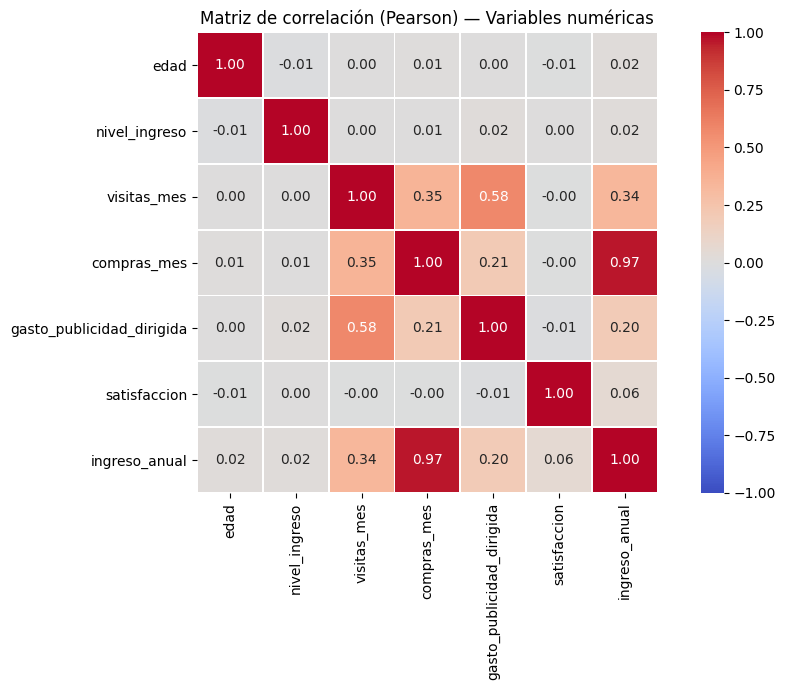

In [ ]:
# Visualizar la matriz de correlación para identificar relaciones
num_cols = [
    'edad',
    'nivel_ingreso',
    'visitas_mes',
    'compras_mes',
    'gasto_publicidad_dirigida',
    'satisfaccion',
    'ingreso_anual'
]

corr_matrix = df[num_cols].corr(method='pearson')

plt.figure(figsize=(10, 7))
sn.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    square=True
)
plt.title('Matriz de correlación (Pearson) — Variables numéricas')
plt.tight_layout()
plt.show()

✍️ **Comentario**:


Observaciones generales (Heatmap)  
Se observa que predominan correlaciones lineales bajas o cercanas a cero entre la mayoría de los pares de variables, sin colinealidad generalizada, aunque destacan dos excepciones importantes: una correlación muy fuerte entre `compras_mes` e `ingreso_anual` ($r \approx 0.97$) y una relación moderada entre `visitas_mes` y `gasto_publicidad_dirigida` ($r \approx 0.58$).

**Observaciones respecto a `ingreso_anual`**
- Presenta una asociación lineal positiva muy fuerte con `compras_mes` ($r \approx 0.97$), lo que sugiere que ambas variables están estrechamente vinculadas y podrían aportar información casi redundante.
- Mantiene correlaciones positivas moderadas o débiles con `visitas_mes` ($r \approx 0.34$) y `gasto_publicidad_dirigida` ($r \approx 0.20$), mientras que variables como `edad`, `nivel_ingreso` y `satisfaccion` muestran vínculos lineales prácticamente nulos.


### Scatterplot general

Con base en los resultados del análisis de correlación, evalúa si es necesario generar un *scatterplot* general.

- **Si decides incluirlo**:
  - Genera el gráfico.
  - Describe brevemente qué patrones o tendencias observas.

- **Si decides no incluirlo**:
  - Explica por qué.

No es necesario generar un gráfico de dispersión general completo sobre las 15,000 filas con las 7 variables numéricas,
ya que el heatmap previo muestra correlaciones lineales bajas en la mayoría de los pares y un `pairplot` de 15,000 registros satura la lectura visual.
En su lugar, conviene concentrarse directamente en los pares más relevantes en el punto **3.3**.

### Scatterplot para pares clave

In [ ]:
# Visualizar pares de variables con relaciones moderadas o fuertes


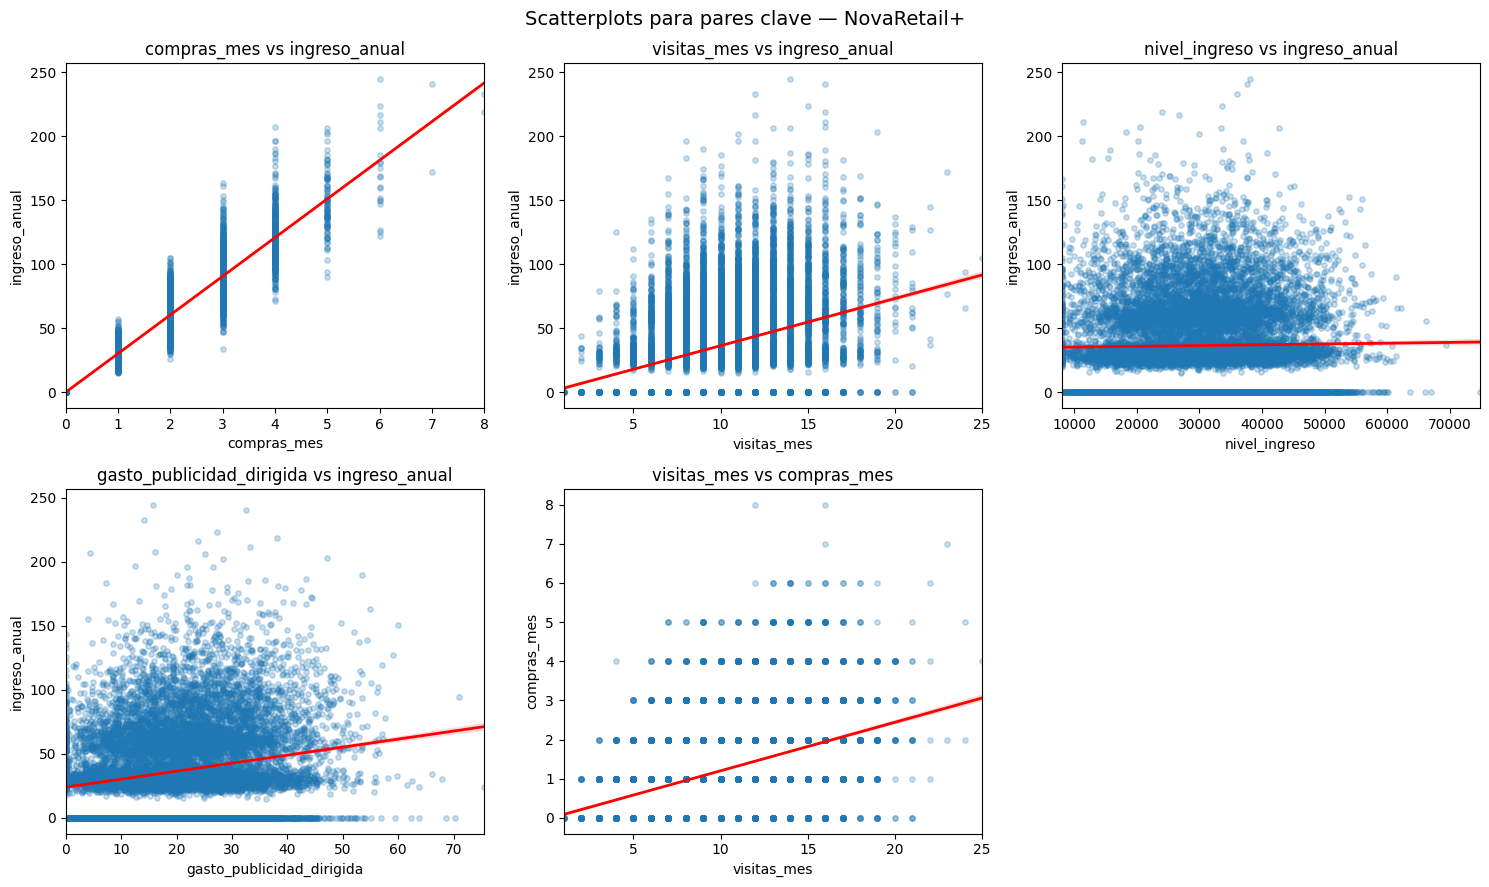

In [ ]:
pares_clave = [
    ('compras_mes', 'ingreso_anual'),
    ('visitas_mes', 'ingreso_anual'),
    ('nivel_ingreso', 'ingreso_anual'),
    ('gasto_publicidad_dirigida', 'ingreso_anual'),
    ('visitas_mes', 'compras_mes')
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for idx, (x_col, y_col) in enumerate(pares_clave):
    sn.regplot(
        data=df,
        x=x_col,
        y=y_col,
        ax=axes[idx],
        scatter_kws={'alpha': 0.25, 's': 15},
        line_kws={'color': 'red', 'linewidth': 2}
    )
    axes[idx].set_title(f'{x_col} vs {y_col}')

# Ocultar el sexto subgráfico sobrante
axes[-1].axis('off')

plt.suptitle('Scatterplots para pares clave — NovaRetail+', fontsize=14)
plt.tight_layout()
plt.show()

✍️ **Comentario**:

Observaciones iniciales (Scatterplot)

**`compras_mes` vs `ingreso_anual`**
- **Dirección:** Positiva y muy pronunciada.
- **Dispersión:** Baja alrededor de la tendencia general; los puntos se distribuyen en bandas estrechas alineadas con los valores discretos de `compras_mes`, con una franja marcada en `ingreso_anual = 0` asociada principalmente a `compras_mes = 0`.
  
- **Outliers:** Existen clientes con altos ingresos anuales en tramos superiores de compras, pero siguen el patrón de bandas sin puntos aislados extremos fuera de tendencia.
  
- **Posible colinealidad:** Alta. Una relación tan ajustada ($r \approx 0.97$) indica un fuerte solapamiento o dependencia directa entre frecuencia de compras e ingreso anual, por lo que conviene revisar cómo se construye `ingreso_anual` antes de usar ambas variables juntas en modelos.

**`visitas_mes` vs `ingreso_anual`**
- **Dirección:** Positiva moderada-baja.
- **Dispersión:** Media-alta; la nube es amplia y presenta una acumulación notoria en `ingreso_anual = 0` a lo largo de distintos niveles de visitas.
- **Outliers:** Se observan clientes con mayor número de visitas mensuales (hasta ~25) y valores altos en `ingreso_anual` (por encima de 150–200).
- **Posible colinealidad:** Baja; el vínculo existe, pero la dispersión es considerable.

**`nivel_ingreso` vs `ingreso_anual`**
- **Dirección:** Prácticamente nula / plana (pendiente cercana a cero).
- **Dispersión:** Alta en todo el rango del ingreso estimado del cliente, con la franja base en `ingreso_anual = 0` y valores superiores dispersos sin formar una banda clara.
  
- **Outliers:** Valores altos de `ingreso_anual` y `nivel_ingreso` (cerca de 75,000), sin un patrón lineal definido entre ambas variables.
- **Posible colinealidad:** No se aprecia colinealidad.

**`gasto_publicidad_dirigida` vs `ingreso_anual`**

- **Dirección:** Positiva débil.
- **Dispersión:** Alta; los datos se concentran en niveles intermedios de gasto publicitario y mantienen una franja densa en `ingreso_anual = 0`.
- **Outliers:** Hay registros con gasto publicitario elevado (por encima de 50–75) y valores altos en `ingreso_anual` sin una relación lineal estrecha.
- **Posible colinealidad:** Baja frente a `ingreso_anual`, aunque conviene tener presente su relación moderada con `visitas_mes` vista en el heatmap.

**`visitas_mes` vs `compras_mes`**
- **Dirección:** Positiva baja-moderada.
- **Dispersión:** Media; `compras_mes` es discreta y toma valores bajos (0 a 8), mientras que `visitas_mes` muestra mayor amplitud, incluyendo una concentración en `compras_mes = 0`.
- **Outliers:** Algunos usuarios con muchas visitas mensuales o compras por encima del promedio (6–8 compras/mes), aunque dentro de un rango acotado.
- **Posible colinealidad:** Baja-moderada; ambas métricas de actividad se relacionan, pero no son redundantes.

## Sección 4 - Coeficientes de correlación y evidencia numérica

En esta sección, se reportan coeficientes que respaldan los patrones
observados visualmente, utilizando el método adecuado según el tipo
de variables.

### Pearson / Spearman

In [ ]:
# Calcular correlación entre variables relevantes
pares_num = [
    ('compras_mes', 'ingreso_anual'),
    ('visitas_mes', 'ingreso_anual'),
    ('nivel_ingreso', 'ingreso_anual'),
    ('gasto_publicidad_dirigida', 'ingreso_anual'),
    ('satisfaccion', 'ingreso_anual'),
    ('edad', 'ingreso_anual'),
    ('visitas_mes', 'compras_mes')
]

resultados_pearson = []
for x, y in pares_num:
    r, p_val = pearsonr(df[x], df[y])
    resultados_pearson.append({
        'par': f'{x} vs {y}',
        'pearson_r': round(r, 4),
        'p_value': f'{p_val:.4e}'
    })

pd.DataFrame(resultados_pearson)

,par,pearson_r,p_value
0,compras_mes vs ingreso_anual,0.9671,0.0000e+00
1,visitas_mes vs ingreso_anual,0.3371,0.0000e+00
2,nivel_ingreso vs ingreso_anual,0.0174,3.2627e-02
3,gasto_publicidad_dirigida vs ingreso_anual,0.1975,9.1693e-132
4,satisfaccion vs ingreso_anual,0.0562,5.8065e-12
5,edad vs ingreso_anual,0.0175,3.2131e-02
6,visitas_mes vs compras_mes,0.3538,0.0000e+00


In [ ]:
# Calcular correlación entre variables relevantes
resultados_comp = []
for x, y in pares_num:
    r_p, p_p = pearsonr(df[x], df[y])
    rho_s, p_s = spearmanr(df[x], df[y])
    resultados_comp.append({
        'par': f'{x} vs {y}',
        'pearson_r': round(r_p, 4),
        'spearman_rho': round(rho_s, 4),
        'diferencia': round(abs(rho_s - r_p), 4),
        'p_value_spearman': f'{p_s:.4e}'
    })

pd.DataFrame(resultados_comp)

,par,pearson_r,spearman_rho,diferencia,p_value_spearman
0,compras_mes vs ingreso_anual,0.9671,0.9675,0.0003,0.0000e+00
1,visitas_mes vs ingreso_anual,0.3371,0.3210,0.0162,0.0000e+00
2,nivel_ingreso vs ingreso_anual,0.0174,0.0250,0.0076,2.1824e-03
3,gasto_publicidad_dirigida vs ingreso_anual,0.1975,0.1850,0.0125,1.3562e-115
4,satisfaccion vs ingreso_anual,0.0562,0.0608,0.0047,8.8596e-14
5,edad vs ingreso_anual,0.0175,0.0161,0.0014,4.8680e-02
6,visitas_mes vs compras_mes,0.3538,0.3329,0.0209,0.0000e+00


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves: dirección, magnitud y posible colinealidad.


Observaciones de correlación

*compras_mes vs ingreso_anual*
- Correlación positiva **muy alta** (`r = 0.9671`, `rho = 0.9675`, diferencia de `0.0003`, `p < 0.001`), lo que sugiere una relación casi lineal y posible colinealidad o solapamiento estrecho entre compras mensuales e ingreso anual.

*visitas_mes vs compras_mes*
- Correlación positiva **baja-moderada** (`r = 0.3538`, `rho = 0.3329`, `p < 0.001`), sin evidencia de colinealidad.

*visitas_mes vs ingreso_anual*
- Correlación positiva **baja-moderada** (`r = 0.3371`, `rho = 0.3210`, `p < 0.001`), sin evidencia de colinealidad.

*gasto_publicidad_dirigida vs ingreso_anual*
- Correlación positiva **débil** (`r = 0.1975`, `rho = 0.1850`, `p < 0.001`), sin evidencia de colinealidad.

*satisfaccion vs ingreso_anual*, *nivel_ingreso vs ingreso_anual* y *edad vs ingreso_anual*
- Correlaciones positivas **prácticamente nulas o muy débiles** (`r` entre `0.0174` y `0.0562`; `rho` entre `0.0161` y `0.0608`), sin colinealidad.

### Punto-biserial

In [ ]:
# Calcular correlación entre variables relevantes
bin_vars = ['miembro_premium', 'abandono']
num_vars_pb = [
    'ingreso_anual',
    'compras_mes',
    'visitas_mes',
    'gasto_publicidad_dirigida',
    'satisfaccion',
    'nivel_ingreso',
    'edad'
]

resultados_pb = []
for b_col in bin_vars:
    for n_col in num_vars_pb:
        r_pb, p_val = pb(df[b_col], df[n_col])
        resultados_pb.append({
            'binaria_vs_numerica': f'{b_col} vs {n_col}',
            'r_biserial': round(r_pb, 4),
            'p_value': f'{p_val:.4e}',
            'media_0': round(df.loc[df[b_col] == 0, n_col].mean(), 2),
            'media_1': round(df.loc[df[b_col] == 1, n_col].mean(), 2)
        })

pd.DataFrame(resultados_pb)

,binaria_vs_numerica,r_biserial,p_value,media_0,media_1
0,miembro_premium vs ingreso_anual,0.0931,3.0943e-30,35.30,44.58
1,miembro_premium vs compras_mes,0.0034,6.7440e-01,1.20,1.22
2,miembro_premium vs visitas_mes,-0.0127,1.2113e-01,10.05,9.93
3,miembro_premium vs gasto_publicidad_dirigida,0.0027,7.3898e-01,20.14,20.22
4,miembro_premium vs satisfaccion,0.0257,1.6215e-03,3.60,3.65
5,miembro_premium vs nivel_ingreso,-0.0056,4.9296e-01,30041.85,29882.85
6,miembro_premium vs edad,0.0046,5.7277e-01,38.24,38.39
7,abandono vs ingreso_anual,-0.0028,7.2947e-01,36.64,36.36
8,abandono vs compras_mes,0.0083,3.0994e-01,1.20,1.23
9,abandono vs visitas_mes,-0.0089,2.7344e-01,10.04,9.96


✍️ **Comentario**:

**Observaciones Punto-biserial**

*miembro_premium vs ingreso_anual*
- Relación **positiva débil** (`r = 0.0931`, `p < 0.001`), siendo el par con mayor efecto relativo en este bloque: los miembros premium registran un promedio mayor de `ingreso_anual` (`44.58`) frente a quienes no lo son (`35.30`).

*abandono vs ingreso_anual*
- Relación **prácticamente nula** (`r = -0.0028`, `p = 0.7295`), con promedios de `ingreso_anual` muy cercanos entre clientes sin abandono (`36.64`) y con abandono (`36.36`).

*miembro_premium vs satisfaccion*
- Relación **positiva muy débil** (`r = 0.0257`, `p = 0.0016`), con medias prácticamente iguales (`3.65` vs. `3.60`).

*abandono vs satisfaccion*
- Relación **negativa muy débil** (`r = -0.0238`, `p = 0.0035`), con una satisfacción promedio ligeramente menor en quienes abandonan (`3.56` vs. `3.61`).

*Resto de pares (`miembro_premium` y `abandono` con `compras_mes`, `visitas_mes`, `gasto_publicidad_dirigida`, `nivel_ingreso` y `edad`)*
- Asociaciones **prácticamente nulas o muy débiles** (`|r| <= 0.0127`) y, salvo los casos anteriores, sin significancia estadística (`p > 0.05`), con promedios muy similares entre categorías.

**Nota:** Dado el tamaño de la muestra (`n = 15,000`), coeficientes pequeños como `0.0257` o `-0.0238` alcanzan significancia estadística (`p < 0.05`), pero su relevancia práctica es limitada.

### V de Cramér

In [ ]:
# Función para calcular V de Cramér
def cramers_v(x, y):
    tabla = pd.crosstab(x, y)
    chi2_stat, _, _, _ = chi2(tabla)
    n = tabla.sum().sum()
    min_dim = min(tabla.shape) - 1
    if min_dim == 0 or n == 0:
        return 0.0
    return np.sqrt(chi2_stat / (n * min_dim))

In [ ]:
# Aplicar V de Cramér en variables relevantes

cat_bin_cols = ['tipo_dispositivo', 'region', 'miembro_premium', 'abandono']

resultados_cramer = []
for i in range(len(cat_bin_cols)):
    for j in range(i + 1, len(cat_bin_cols)):
        c1, c2 = cat_bin_cols[i], cat_bin_cols[j]
        tabla = pd.crosstab(df[c1], df[c2])
        chi2_stat, p_val, dof, _ = chi2(tabla)
        v_val = cramers_v(df[c1], df[c2])
        resultados_cramer.append({
            'par': f'{c1} vs {c2}',
            'v_cramer': round(v_val, 4),
            'chi2': round(chi2_stat, 2),
            'p_value': f'{p_val:.4e}'
        })

pd.DataFrame(resultados_cramer)

,par,v_cramer,chi2,p_value
0,tipo_dispositivo vs region,0.0124,4.60,5.9648e-01
1,tipo_dispositivo vs miembro_premium,0.0197,5.84,5.4031e-02
2,tipo_dispositivo vs abandono,0.0072,0.79,6.7456e-01
3,region vs miembro_premium,0.0126,2.37,4.9893e-01
4,region vs abandono,0.0154,3.57,3.1165e-01
5,miembro_premium vs abandono,0.1202,216.79,4.5392e-49


✍️ **Comentario**:

Observaciones V de Cramér
*miembro_premium vs abandono*
- Asociación **baja / débil pero estadísticamente significativa** (`V = 0.1202`, `chi2 = 216.79`, `p < 0.001`), siendo el par categórico con mayor asociación relativa dentro de este grupo.

*Resto de pares (`tipo_dispositivo vs region`, `tipo_dispositivo vs miembro_premium`, `tipo_dispositivo vs abandono`, `region vs miembro_premium` y `region vs abandono`)*
- Asociaciones **prácticamente nulas o muy débiles** (`V` entre `0.0072` y `0.0197`) y sin significancia estadística al nivel habitual de `0.05` (`p > 0.05`), lo que indica independencia práctica entre región, dispositivo, membresía y abandono.


## Sección 5 - Interpretación de resultados para el negocio

Cada hallazgo  debe incluir:
1) Evidencia visual (si aplica)
2) Evidencia numérica  
3) Interpretación (no causal)  
4) No podemos afirmar
5) Implicación de negocio

---

### Hallazgo 1

- **Evidencia visual:** El *heatmap* y el *scatterplot* de `compras_mes` vs `ingreso_anual` muestran una tendencia positiva muy marcada, con puntos agrupados en **bandas estrechas alrededor de la línea de tendencia** (baja dispersión para cada nivel de compras) y una concentración notable en `ingreso_anual = 0` asociada principalmente a `compras_mes = 0`.
- **Evidencia numérica:** Correlación de Pearson `r = 0.9671` y Spearman `rho = 0.9675` (`p < 0.001`, diferencia de `0.0003`).
- **Interpretación:** Una mayor frecuencia de compras mensuales se asocia de forma muy fuerte y casi lineal con un mayor `ingreso_anual`.
- **No podemos afirmar:** No permite establecer causalidad directa ni descartar una relación o dependencia estrecha en la definición/construcción de `ingreso_anual` a partir de la actividad de compra (especialmente dado que `compras_mes = 0` coincide de forma marcada con `ingreso_anual = 0`).
- **Implicación de negocio:** Priorizar la recurrencia de compra en el análisis de valor del cliente y revisar cómo se construye `ingreso_anual` respecto a `compras_mes` antes de incluir ambas variables juntas en modelos predictivos.


### Hallazgo 2

 Visitas, publicidad dirigida y membresía `premium`
*Evidencia visual:* Nubes dispersas con tendencia positiva suave o moderada en `visitas_mes` y `gasto_publicidad_dirigida`, y valores altos aislados en `ingreso_anual`.
*Evidencia numérica:* `visitas_mes` con `compras_mes` (`r = 0.3538`, `rho = 0.3329`) e `ingreso_anual` (`r = 0.3371`, `rho = 0.3210`); `gasto_publicidad_dirigida vs ingreso_anual` (`r = 0.1975`, `rho = 0.1850`); `miembro_premium vs ingreso_anual` (`r_pb = 0.0931`, medias `44.58` vs. `35.30`) y `vs abandono` (`V = 0.1202`); `edad`, `nivel_ingreso` y `satisfaccion` con vínculos muy débiles o nulos (`|r| <= 0.0562`).
*Interpretación:* Las visitas y la pauta dirigida muestran vínculos moderados o débiles, mientras que edad, nivel de ingreso y satisfacción apenas se asocian con `ingreso_anual`.
*No podemos afirmar:* No se puede concluir que más tráfico, anuncios o membresía `premium` causen directamente mayores ingresos o menor abandono sin pruebas controladas.
*Implicación de negocio:* Evaluar la eficiencia de campañas y validar efectos de retención o membresía mediante experimentos antes de escalar acciones.


## Sección 6 - Limitaciones y próximos pasos

### **Limitaciones**
 - **Correlación ≠ causalidad:** Al tratarse de un análisis observacional y exploratorio, las asociaciones encontradas no prueban que una variable provoque cambios en otra.
- **Posibles variables omitidas y factores confusores:** No se observan variables clave como ticket promedio, categoría de producto, promociones o estacionalidad, además de existir desbalance en variables binarias como `miembro_premium` (**13.93%** en `1`).
- **Posible colinealidad / solapamiento métrico:** La correlación muy alta entre `compras_mes` e `ingreso_anual` (`r = 0.9671`, `rho = 0.9675`) obliga a revisar cómo se relacionan ambas variables antes de usarlas juntas en modelos predictivos.
- **Asimetría y valores atípicos:** Variables como `ingreso_anual` y `gasto_publicidad_dirigida` presentan dispersión y valores máximos elevados que conviene vigilar.
  

### **Próximos pasos**

- **Probar segmentación adicional**
  - Comparar cohortes por `miembro_premium` (**0** vs. **1**) y `abandono` (**0** vs. **1**) cruzando frecuencia de compras y satisfacción.
  - Evaluar diferencias por `tipo_dispositivo` y `region` sobre métricas de comportamiento y valor.
- **Diseñar pruebas A/B y experimentos controlados**
  - Validar si incentivar la recurrencia de compra, ajustar la pauta dirigida o promover la membresía `premium` genera un impacto causal real en `ingreso_anual` y retención.
- **Profundizar el modelado y la calidad del dato**
  - Revisar la definición operativa de `ingreso_anual` frente a `compras_mes` y probar análisis multivariados o modelos no lineales controlando por posibles variables confusoras.